In [47]:
import polars as pl
import numpy as np
import seaborn as sns
import numpy.typing as npt
import matplotlib.pyplot as plt

In [17]:
df_cpu_active = pl.read_csv("../data/alibaba-2020/generated/cpu_active_power_min.csv")
df_cpu_active = df_cpu_active.sort("time")
df_cpu_active

time,power
i64,f64
0,3.535193
2048,32.736258
2079,74.989406
2095,77.614302
2542,88.973482
…,…
73951,166.422279
73952,125.317397
73953,55.765081


In [18]:
df_cpu_idle = pl.read_csv("../data/alibaba-2020/generated/cpu_idle_power_min.csv")
df_cpu_idle = df_cpu_idle.sort("time")
df_cpu_idle

time,power
i64,f64
0,198900.0
1,198900.0
2,198900.0
3,198900.0
4,198900.0
…,…
73950,198900.0
73951,198900.0
73952,198900.0


In [19]:
df_gpu_active = pl.read_csv("../data/alibaba-2020/generated/gpu_active_power_min.csv")
df_gpu_active = df_gpu_active.sort("time")
df_gpu_active

time,power
i64,f64
0,1044.318807
2049,1060.481071
2080,1227.239776
2095,1243.948805
2542,1270.34874
…,…
73951,10493.458069
73952,6665.439101
73953,5424.405504


In [20]:
df_gpu_idle = pl.read_csv("../data/alibaba-2020/generated/gpu_idle_power_min.csv")
df_gpu_idle = df_gpu_idle.sort("time")
df_gpu_idle

time,power
i64,f64
0,110616.0
1,110616.0
2,110616.0
3,110616.0
4,110616.0
…,…
73950,110299.0
73951,110494.0
73952,110559.0


In [52]:
def combine_power_dfs(dfs: list[pl.DataFrame]) -> npt.NDArray[np.float32]:
    res_size = max([df["time"].max() for df in dfs])
    power_consumption = np.zeros(res_size, dtype=np.float32)
    prev_time = df_cpu_active["time"][0]
    prev_power = df_cpu_active["power"][0]
    for df in dfs:
        for time, power in df[1:].iter_rows():
            power_consumption[prev_time:time] += prev_power
            prev_power = power
            prev_time = time
    return power_consumption

<Axes: title={'center': 'CPU Power Consumption'}, xlabel='Time (min)', ylabel='Power (watt)'>

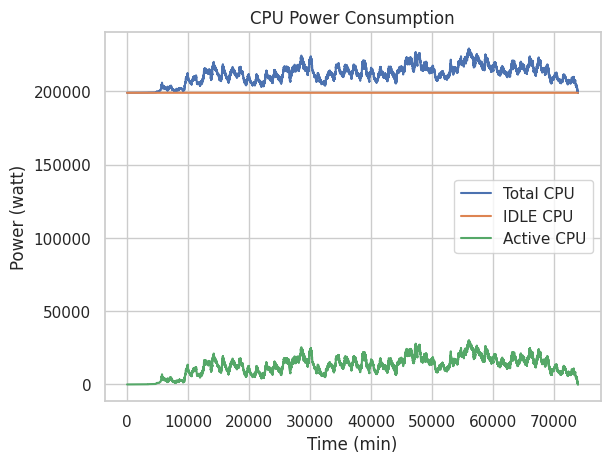

In [53]:
power_cpu = combine_power_dfs([df_cpu_active, df_cpu_idle])
sns.set_theme(style="whitegrid")
plt.title("CPU Power Consumption")
plt.xlabel('Time (min)')
plt.ylabel('Power (watt)')
sns.lineplot(x=np.arange(len(power_cpu[1:-1])), y=power_cpu[1:-1], label="Total CPU")
sns.lineplot(df_cpu_idle, x="time", y="power", label="IDLE CPU")
sns.lineplot(df_cpu_active, x="time", y="power", label="Active CPU")

<Axes: title={'center': 'GPU Power Consumption'}, xlabel='Time (min)', ylabel='Power (watt)'>

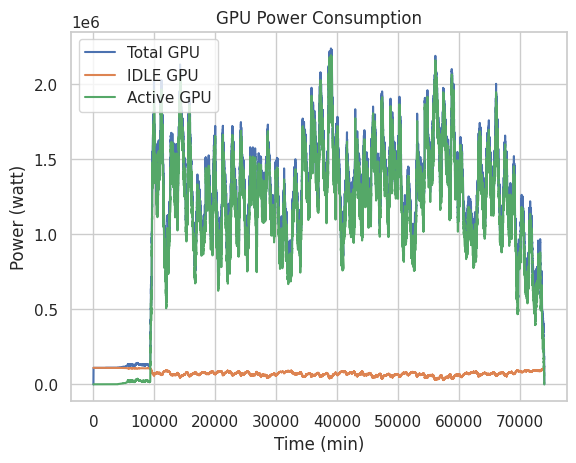

In [54]:
power_gpu = combine_power_dfs([df_gpu_active, df_gpu_idle])
sns.set_theme(style="whitegrid")
plt.title('GPU Power Consumption')
plt.xlabel('Time (min)')
plt.ylabel('Power (watt)')
sns.lineplot(x=np.arange(len(power_gpu)), y=power_gpu, label="Total GPU")
sns.lineplot(df_gpu_idle, x="time", y="power", label="IDLE GPU")
sns.lineplot(df_gpu_active, x="time", y="power", label="Active GPU")

<Axes: title={'center': 'GPU+CPU Power Consumption'}, xlabel='Time (min)', ylabel='Power (watt)'>

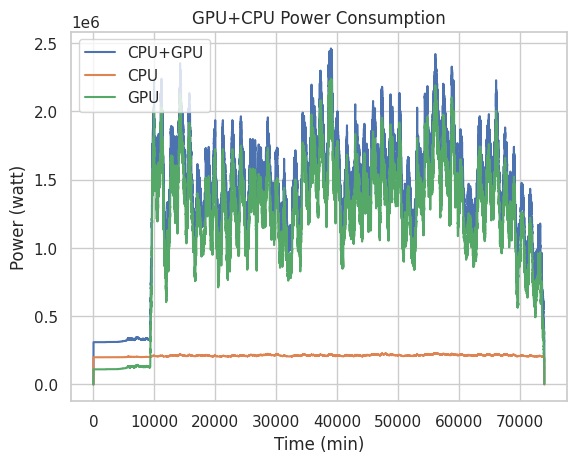

In [55]:
power_cpu_gpu = power_cpu + power_gpu
sns.set_theme(style="whitegrid")
plt.title('GPU+CPU Power Consumption')
plt.xlabel('Time (min)')
plt.ylabel('Power (watt)')
sns.lineplot(x=np.arange(len(power_cpu_gpu)), y=power_cpu_gpu, label="CPU+GPU")
sns.lineplot(x=np.arange(len(power_cpu)), y=power_cpu, label="CPU")
sns.lineplot(x=np.arange(len(power_gpu)), y=power_gpu, label="GPU")

<Axes: title={'center': 'Data Center Power Consumption'}, xlabel='Time (min)', ylabel='Power (watt)'>

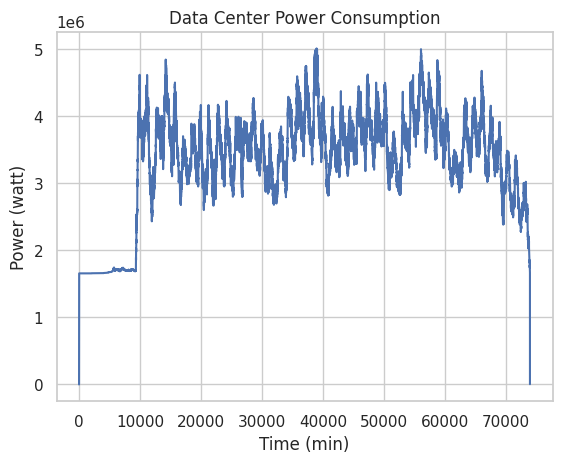

In [56]:
cpu_power_percent = 0.2
power_server = power_cpu / cpu_power_percent + power_gpu
PUE = 1.5
power_dc = PUE * power_server
plt.title('Data Center Power Consumption')
plt.xlabel('Time (min)')
plt.ylabel('Power (watt)')
sns.set_theme(style="whitegrid")
sns.lineplot(x=np.arange(len(power_dc)), y=power_dc)